In [2]:
%pip install -q pandas matplotlib pillow imagehash scikit-learn tqdm ipywidgets torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os

RAW_DIR = r"D:\Data Mining\Dataset\dataset"
assert os.path.isdir(RAW_DIR), "Folder tidak ditemukan"
print("OK:", RAW_DIR)

OK: D:\Data Mining\Dataset\dataset


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
is_img = lambda f: os.path.splitext(f)[1].lower() in IMG_EXT

for root, dirs, fs in sorted(os.walk(RAW_DIR)):
    n = sum(is_img(f) for f in fs)
    depth = root[len(RAW_DIR):].count(os.sep)
    if n > 0 or depth <= 2:
        print("  " * depth + os.path.basename(root) + f"/   ({n} gambar)")

dataset/   (0 gambar)
  Calculus/   (0 gambar)
    Calculus/   (1296 gambar)
  Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/   (0 gambar)
    Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/   (0 gambar)
          train/   (1493 gambar)
          val/   (49 gambar)
  Data caries/   (0 gambar)
    Data caries/   (0 gambar)
        preview/   (2382 gambar)
        done/   (219 gambar)
  Gingivitis/   (0 gambar)
    Gingivitis/   (2349 gambar)
  Mouth Ulcer/   (0 gambar)
    Mouth Ulcer/   (0 gambar)
        preview/   (2541 gambar)
        ulcer original dataset/   (265 gambar)
  Tooth Discoloration/   (0 gambar)
    Tooth Discoloration/   (0 gambar)
        preview/   (1834 gambar)
        tooth discoloration original dataset/   (183 gambar)
  hypodontia/   (0 gambar)
    hypodontia/   (1251 gambar)


In [5]:
EXCLUDE_KEYWORDS = ["augment", "preview", "yolo"]
CLASSES = {"caries": "caries", "calculus": "calculus", "gingivitis": "gingivitis"}
NEAR_DUP_THRESHOLD = 6
SEED = 42

In [6]:
import pandas as pd

rows, skipped = [], 0
for root, _, fs in os.walk(RAW_DIR):
    parts = [p.lower() for p in os.path.relpath(root, RAW_DIR).split(os.sep)]
    excluded = any(k in p for p in parts for k in EXCLUDE_KEYWORDS)
    label = None
    for p in reversed(parts):
        for key, name in CLASSES.items():
            if key in p:
                label = name
                break
        if label:
            break
    if label is None:
        continue
    for f in fs:
        if is_img(f):
            if excluded:
                skipped += 1
                continue
            rows.append({"path": os.path.join(root, f), "label": label})

df = pd.DataFrame(rows)
print("Gambar dilewati (preview/yolo/augment):", skipped)
print("Total dipakai:", len(df))
print(df.label.value_counts())

Gambar dilewati (preview/yolo/augment): 3924
Total dipakai: 3864
label
gingivitis    2349
calculus      1296
caries         219
Name: count, dtype: int64


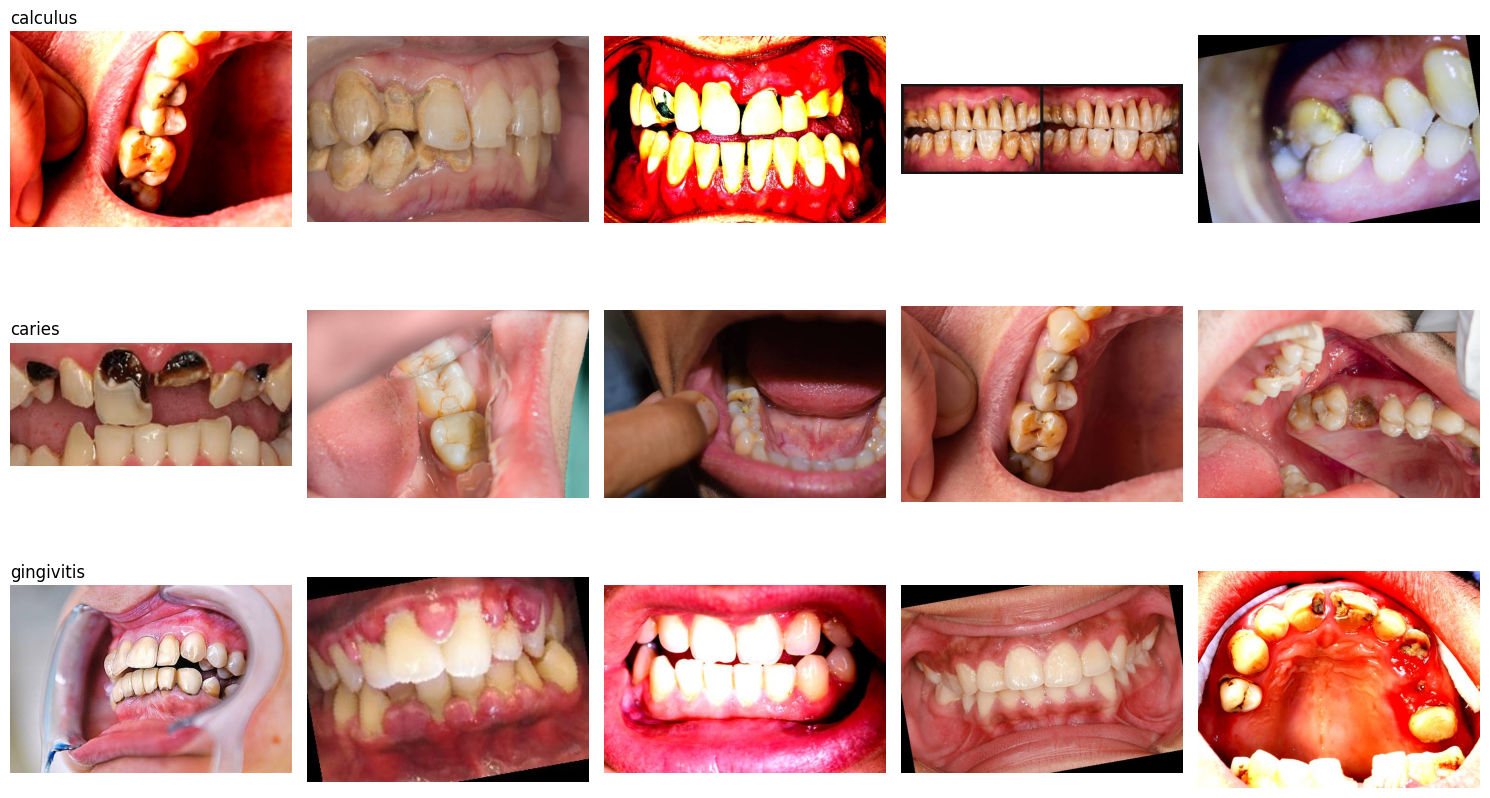

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(df.label.unique())
fig, axes = plt.subplots(len(classes), 5, figsize=(15, 3 * len(classes)))
for r, c in enumerate(classes):
    sample = df[df.label == c].sample(5, random_state=SEED)
    for k, p in enumerate(sample.path):
        axes[r, k].imshow(Image.open(p).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left", fontsize=12)
plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import imagehash
from tqdm.auto import tqdm

H, HF = [], []
for p in tqdm(df.path):
    im = Image.open(p).convert("RGB")
    H.append(imagehash.phash(im).hash.flatten())
    HF.append(imagehash.phash(im.transpose(Image.FLIP_LEFT_RIGHT)).hash.flatten())
A = np.array(H).astype(np.float32)
Af = np.array(HF).astype(np.float32)

def dist(X, Y):
    return 64 - (X @ Y.T + (1 - X) @ (1 - Y).T)

n = len(df)
parent = list(range(n))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

CH = 500
for s in tqdm(range(0, n, CH)):
    blk = A[s:s + CH]
    d = np.minimum(dist(blk, A), dist(blk, Af))
    ii, jj = np.where(d <= NEAR_DUP_THRESHOLD)
    for i, j in zip(ii, jj):
        if s + i < j:
            union(s + i, j)

df["group"] = [find(i) for i in range(n)]
sizes = df.group.value_counts()
imgs_in_dup = sizes[sizes > 1].sum()
print(f"Total gambar        : {n}")
print(f"Kelompok unik       : {len(sizes)}")
print(f"Kelompok berisi >1  : {(sizes > 1).sum()}")
print(f"Gambar yang punya kembaran/mirip: {imgs_in_dup} ({100 * imgs_in_dup / n:.1f}%)")
print("Kelompok dengan label campur:", int((df.groupby('group').label.nunique() > 1).sum()))
print(df.groupby('label').group.nunique())

  0%|          | 0/3864 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Total gambar        : 3864
Kelompok unik       : 1167
Kelompok berisi >1  : 514
Gambar yang punya kembaran/mirip: 3211 (83.1%)
Kelompok dengan label campur: 179
label
calculus      394
caries        190
gingivitis    766
Name: group, dtype: int64


In [9]:
pairs = []
for s in range(0, n, CH):
    blk = A[s:s + CH]
    d = np.minimum(dist(blk, A), dist(blk, Af))
    ii, jj = np.where(d <= 8)
    for i, j in zip(ii, jj):
        if s + i < j:
            pairs.append((s + i, j, d[i, j]))
pairs = np.array(pairs)
print("Pasangan gambar mirip:", len(pairs))

def cluster(th):
    par = list(range(n))
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]
            x = par[x]
        return x
    for i, j, dd in pairs:
        if dd <= th:
            a, b = f(int(i)), f(int(j))
            if a != b:
                par[b] = a
    return np.array([f(i) for i in range(n)])

for th in [0, 2, 4, 6, 8]:
    g = cluster(th)
    sz = pd.Series(g).value_counts()
    mixed = int((df.assign(g=g).groupby("g").label.nunique() > 1).sum())
    print(f"ambang {th}: kelompok {len(sz)}, terbesar {sz.iloc[0]}, "
          f"punya kembaran {100 * sz[sz > 1].sum() / n:.1f}%, label campur {mixed}")

Pasangan gambar mirip: 20217
ambang 0: kelompok 1776, terbesar 47, punya kembaran 72.5%, label campur 283
ambang 2: kelompok 1515, terbesar 56, punya kembaran 77.4%, label campur 237
ambang 4: kelompok 1301, terbesar 56, punya kembaran 80.7%, label campur 195
ambang 6: kelompok 1167, terbesar 56, punya kembaran 83.1%, label campur 179
ambang 8: kelompok 1103, terbesar 56, punya kembaran 84.4%, label campur 175


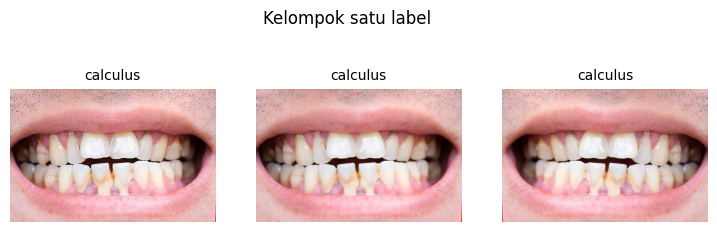

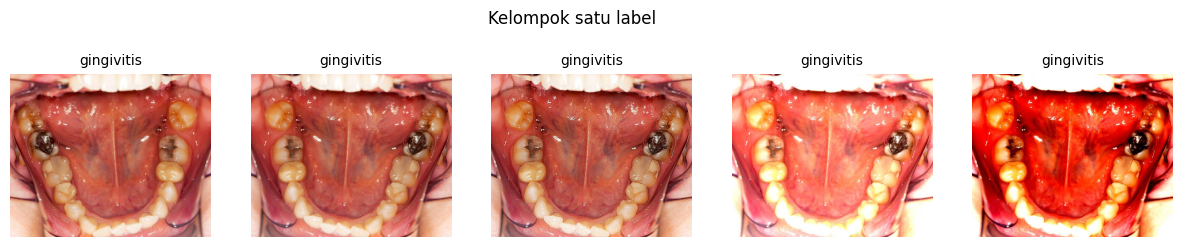

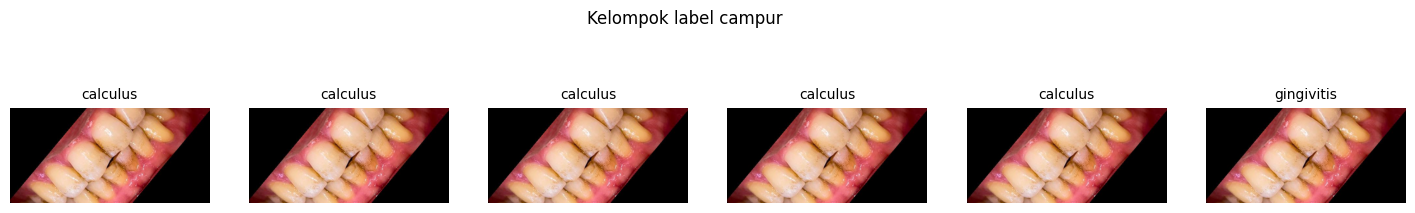

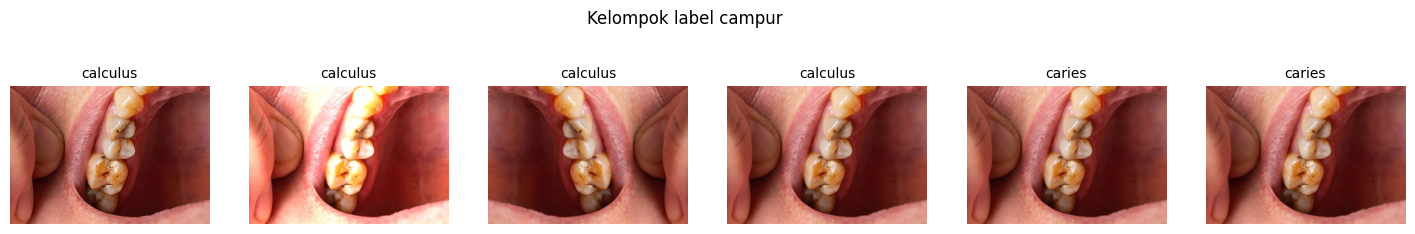

In [10]:
g4 = cluster(4)
tmp = df.assign(g=g4)
multi = tmp.groupby("g").filter(lambda x: len(x) >= 3)
mixed_groups = [k for k, v in multi.groupby("g") if v.label.nunique() > 1]
plain_groups = [k for k, v in multi.groupby("g") if v.label.nunique() == 1]

def show(gid, title):
    sub = tmp[tmp.g == gid].head(6)
    fig, axes = plt.subplots(1, len(sub), figsize=(3 * len(sub), 3))
    axes = np.atleast_1d(axes)
    for ax, (_, row) in zip(axes, sub.iterrows()):
        ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(row.label, fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

import random
random.seed(1)
for gid in random.sample(plain_groups, min(2, len(plain_groups))):
    show(gid, "Kelompok satu label")
for gid in random.sample(mixed_groups, min(2, len(mixed_groups))):
    show(gid, "Kelompok label campur")

In [11]:
print([n for n in dir() if not n.startswith("_")])

['A', 'Af', 'CH', 'CLASSES', 'EXCLUDE_KEYWORDS', 'H', 'HF', 'IMG_EXT', 'Image', 'In', 'NEAR_DUP_THRESHOLD', 'Out', 'RAW_DIR', 'SEED', 'axes', 'blk', 'c', 'classes', 'cluster', 'd', 'depth', 'df', 'dirs', 'dist', 'excluded', 'exit', 'f', 'fig', 'find', 'fs', 'g', 'g4', 'get_ipython', 'gid', 'i', 'ii', 'im', 'imagehash', 'imgs_in_dup', 'is_img', 'j', 'jj', 'k', 'key', 'label', 'mixed', 'mixed_groups', 'multi', 'n', 'name', 'np', 'open', 'os', 'p', 'pairs', 'parent', 'parts', 'pd', 'plain_groups', 'plt', 'quit', 'r', 'random', 'root', 'rows', 's', 'sample', 'show', 'sizes', 'skipped', 'sz', 'th', 'tmp', 'tqdm', 'union']


In [12]:
print("df:", df.shape)
print(df.columns.tolist())
print(df.head(3))
print()
for nm in ["H", "HF", "A", "Af", "dist", "pairs"]:
    v = globals()[nm]
    print(nm, type(v).__name__, getattr(v, "shape", None) or (len(v) if hasattr(v, "__len__") else v))
print("NEAR_DUP_THRESHOLD =", NEAR_DUP_THRESHOLD)

df: (3864, 3)
['path', 'label', 'group']
                                                path     label  group
0  D:\Data Mining\Dataset\dataset\Calculus\Calcul...  calculus      0
1  D:\Data Mining\Dataset\dataset\Calculus\Calcul...  calculus      1
2  D:\Data Mining\Dataset\dataset\Calculus\Calcul...  calculus      2

H list 3864
HF list 3864
A ndarray (3864, 64)
Af ndarray (3864, 64)
dist function <function dist at 0x000001CC77010B40>
pairs ndarray (20217, 3)
NEAR_DUP_THRESHOLD = 6


In [13]:
import inspect
print(inspect.getsource(cluster))
print(inspect.getsource(union))

def cluster(th):
    par = list(range(n))
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]
            x = par[x]
        return x
    for i, j, dd in pairs:
        if dd <= th:
            a, b = f(int(i)), f(int(j))
            if a != b:
                par[b] = a
    return np.array([f(i) for i in range(n)])

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra



In [15]:
print("jarak di pairs: min", pairs[:, 2].min(), "| max", pairs[:, 2].max())

rows = []
for th in [0, 2, 4, 6, 8]:
    g = cluster(th)
    t = df[["label"]].copy()
    t["g"] = g
    size = t.groupby("g")["label"].transform("size")
    nlab = t.groupby("g")["label"].nunique()
    per = t.groupby("label")["g"].nunique()
    rows.append({
        "ambang": th,
        "kelompok": t["g"].nunique(),
        "% punya kembaran": round((size > 1).mean() * 100, 1),
        "kelompok campur": int((nlab > 1).sum()),
        "unik calculus": per.get("calculus"),
        "unik caries": per.get("caries"),
        "unik gingivitis": per.get("gingivitis"),
    })

print(pd.DataFrame(rows).to_string(index=False))

jarak di pairs: min 0.0 | max 8.0
 ambang  kelompok  % punya kembaran  kelompok campur  unik calculus  unik caries  unik gingivitis
      0      1776              72.5              283            643          193             1227
      2      1515              77.4              237            535          191             1030
      4      1301              80.7              195            448          191              861
      6      1167              83.1              179            394          190              766
      8      1103              84.4              175            376          188              718


In [16]:
df["group6"] = cluster(6)

g = df.groupby("group6")["label"]
mix = g.agg(lambda s: tuple(sorted(set(s))))
size = g.size()
cm = pd.DataFrame({"kombinasi": mix, "ukuran": size})
cm = cm[cm["kombinasi"].apply(len) > 1]

print("Jumlah kelompok campur:", len(cm))
print()
print(cm.groupby("kombinasi")["ukuran"].agg(["count", "sum"])
        .rename(columns={"count": "jumlah kelompok", "sum": "jumlah gambar"}))

Jumlah kelompok campur: 179

                                jumlah kelompok  jumlah gambar
kombinasi                                                     
(calculus, caries)                            3             21
(calculus, caries, gingivitis)                4             89
(calculus, gingivitis)                      169           1371
(caries, gingivitis)                          3             20


In [17]:
mixed_ids = cm.index
sub = df[df["group6"].isin(mixed_ids)]

print("Gambar di kelompok campur, per kelas:")
print(sub["label"].value_counts())
print()
print("Total per kelas (semua data):")
print(df["label"].value_counts())
print()
print("Ukuran kelompok campur:")
print(cm["ukuran"].describe())
print()
print("5 kelompok campur terbesar:")
print(cm.sort_values("ukuran", ascending=False).head(5))

Gambar di kelompok campur, per kelas:
label
gingivitis    766
calculus      721
caries         14
Name: count, dtype: int64

Total per kelas (semua data):
label
gingivitis    2349
calculus      1296
caries         219
Name: count, dtype: int64

Ukuran kelompok campur:
count    179.000000
mean       8.385475
std        9.858665
min        2.000000
25%        2.000000
50%        5.000000
75%        8.000000
max       56.000000
Name: ukuran, dtype: float64

5 kelompok campur terbesar:
                     kombinasi  ukuran
group6                                
68      (calculus, gingivitis)      56
201     (calculus, gingivitis)      48
178     (calculus, gingivitis)      48
250     (calculus, gingivitis)      42
101     (calculus, gingivitis)      40


In [18]:
bersih = df[~df["group6"].isin(cm.index)].copy()

print("Gambar per kelas:")
print(bersih["label"].value_counts())
print()
print("Kelompok unik per kelas:")
print(bersih.groupby("label")["group6"].nunique())
print()
print("Total gambar:", len(bersih), "| total kelompok:", bersih["group6"].nunique())

bersih.to_csv("data_bersih_ambang6.csv", index=False)

Gambar per kelas:
label
gingivitis    1583
calculus       575
caries         205
Name: count, dtype: int64

Kelompok unik per kelas:
label
calculus      218
caries        180
gingivitis    590
Name: group6, dtype: int64

Total gambar: 2363 | total kelompok: 988


In [19]:
import os, glob

print("Isi Dataset:")
for x in sorted(os.listdir(r"D:\Data Mining\Dataset")):
    print("  ", x)

print()
print("Semua file CSV di bawah Dataset:")
for f in glob.glob(r"D:\Data Mining\Dataset\**\*.csv", recursive=True):
    print("  ", f)
    

Isi Dataset:
   dataset
   dataset.zip

Semua file CSV di bawah Dataset:
   D:\Data Mining\Dataset\dataset\test\_classes.csv
   D:\Data Mining\Dataset\dataset\train\_classes.csv
   D:\Data Mining\Dataset\dataset\valid\_classes.csv


In [20]:
import os, shutil

SRC = r"D:\Data Mining\Dataset\dataset"
DST = r"D:\Data Mining\Dataset\roboflow_dental_project"
os.makedirs(DST, exist_ok=True)

for nama in ["train", "valid", "test"]:
    s = os.path.join(SRC, nama)
    d = os.path.join(DST, nama)
    if os.path.isdir(s) and not os.path.exists(d):
        shutil.move(s, d)
        print("dipindah:", nama)
    else:
        print("dilewati:", nama)

print()
print("Isi dataset (Kaggle):", sorted(os.listdir(SRC)))
print()
for nama in ["train", "valid", "test"]:
    p = os.path.join(DST, nama)
    files = os.listdir(p)
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    print(f"{nama}: {len(imgs)} gambar")

dipindah: train
dipindah: valid
dipindah: test

Isi dataset (Kaggle): ['Calculus', 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset', 'Data caries', 'Gingivitis', 'Mouth Ulcer', 'README.dataset.txt', 'README.roboflow.txt', 'Tooth Discoloration', 'hypodontia']

train: 6993 gambar
valid: 1997 gambar
test: 996 gambar


In [21]:
import os, shutil
import pandas as pd

SRC = r"D:\Data Mining\Dataset\dataset"
DST = r"D:\Data Mining\Dataset\roboflow_dental_project"

for nama in ["README.dataset.txt", "README.roboflow.txt"]:
    s = os.path.join(SRC, nama)
    d = os.path.join(DST, nama)
    if os.path.exists(s) and not os.path.exists(d):
        shutil.move(s, d)
        print("dipindah:", nama)

print()
for nama in ["README.dataset.txt", "README.roboflow.txt"]:
    print("=====", nama)
    print(open(os.path.join(DST, nama), encoding="utf-8", errors="ignore").read()[:1500])
    print()

for sp in ["train", "valid", "test"]:
    d = pd.read_csv(os.path.join(DST, sp, "_classes.csv"))
    d.columns = [c.strip() for c in d.columns]
    print(sp, "| baris:", len(d))
    print(d.iloc[:, 1:].sum().to_string())
    print()


===== README.dataset.txt
# dental_project > 2024-04-11 9:51pm
https://universe.roboflow.com/classification-kogl6/dental_project-4qdtp

Provided by a Roboflow user
License: CC BY 4.0



===== README.roboflow.txt

dental_project - v1 2024-04-11 9:51pm

This dataset was exported via roboflow.com on April 11, 2024 at 7:53 PM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-trained models, visit https://universe.roboflow.com

The dataset includes 9986 images.
Caries are annotated in Multi-Class Classification format.

The followin

In [22]:
import os, pandas as pd

DST = r"D:\Data Mining\Dataset\roboflow_dental_project"

txt = open(os.path.join(DST, "README.roboflow.txt"), encoding="utf-8", errors="ignore").read()
kata = ["augment", "preprocess", "resize", "auto-orient", "flip", "rotat",
        "bright", "blur", "noise", "crop", "shear", "saturation", "exposure"]
for line in txt.splitlines():
    if any(k in line.lower() for k in kata):
        print("README:", line.strip())
print()

for sp in ["train", "valid", "test"]:
    d = pd.read_csv(os.path.join(DST, sp, "_classes.csv"))
    d.columns = [c.strip() for c in d.columns]
    print(sp, "| baris:", len(d))
    print(d.iloc[:, 1:].sum().to_string())
    base = d.iloc[:, 0].str.replace(r"\.rf\.[0-9a-f]+", "", regex=True)
    print("nama dasar unik:", base.nunique(), "dari", len(d))
    print()

README: * Auto-orientation of pixel data (with EXIF-orientation stripping)
README: * Resize to 640x640 (Stretch)
README: No image augmentation techniques were applied.

train | baris: 6993
Cavity            1243
Fillings          1512
Implant           1009
caries            1565
decay             1646
earlydecay         141
infected-teeth     835
teeth              797
nama dasar unik: 2311 dari 6993

valid | baris: 1997
Cavity            327
Fillings          420
Implant           255
caries            481
decay             479
earlydecay         37
infected-teeth    247
teeth             207
nama dasar unik: 1235 dari 1997

test | baris: 996
Cavity            164
Fillings          212
Implant           143
caries            245
decay             208
earlydecay         26
infected-teeth    121
teeth             108
nama dasar unik: 783 dari 996



contoh nama file:
0     0675_jpg.rf.0955a282d470fd9215cd338dd1c3cc4d.jpg
1    -content-drive-MyDrive-ilia_iaaa_all_data-2_25...
2     1538_jpg.rf.0962a4c082eefc3cb104d3476f0ba0a8.jpg
3    -content-drive-MyDrive-ilia_iaaa_all_data-1_2_...
4     0468_jpg.rf.09013e8eb6683872ad28656d1dde8d65.jpg



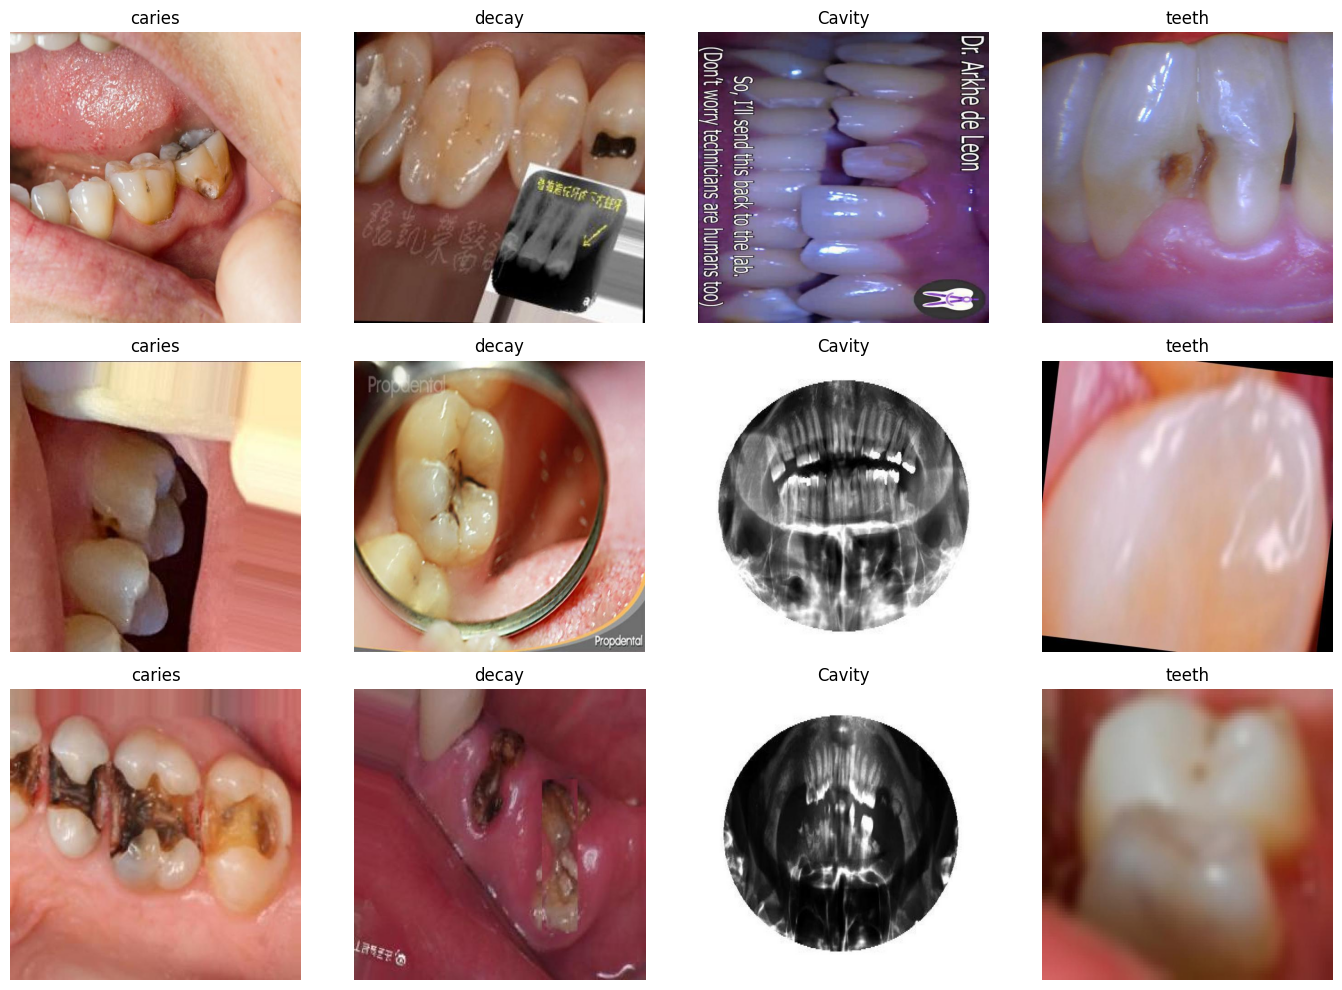

In [23]:
import os, random
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

DST = r"D:\Data Mining\Dataset\roboflow_dental_project"
d = pd.read_csv(os.path.join(DST, "train", "_classes.csv"))
d.columns = [c.strip() for c in d.columns]
fn = d.columns[0]

print("contoh nama file:")
print(d[fn].head(5).to_string())
print()

random.seed(1)
pilih = []
for kls in ["caries", "decay", "Cavity", "teeth"]:
    idx = d.index[d[kls] == 1].tolist()
    pilih += [(kls, i) for i in random.sample(idx, 3)]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, (kls, i) in zip(axes.T.flatten(), pilih):
    ax.imshow(Image.open(os.path.join(DST, "train", d.loc[i, fn])))
    ax.set_title(kls)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [24]:
import numpy as np

df["group6"] = cluster(6)
df.to_csv("df_semua_ambang6.csv", index=False)
np.save("hash_A.npy", A)
np.save("hash_Af.npy", Af)
np.save("pairs.npy", pairs)
print("tersimpan:", df.shape, A.shape, Af.shape, pairs.shape)

tersimpan: (3864, 4) (3864, 64) (3864, 64) (20217, 3)
